<a href="https://colab.research.google.com/github/Luisen25/ELe/blob/main/Difusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1) difusión:
#### Un soluto cruza la membrana por gradiente de concentración

Un compartimento de dializado de volumen constante V, separado de la sangre por una membrana. El soluto pasa solo por difusión, y la sangre mantiene su concentración Cp constante.

La ley de Fick, aplicada a una membrana completa, dice que el flujo es proporcional a la diferencia de concentración:

###J = PS · (Cp − Cd)

PS es el producto permeabilidad por superficie (mL/min). Es el “coeficiente de transferencia” de la membrana para ese soluto. Con el balance de masa del dializado, dN/dt = J y Cd = N/V, queda:

###dCd/dt = (PS / V) · (Cp − Cd)







La concentración se acerca al equilibrio con constante de tiempo τ = V / PS. Eso es lo que vamos a calcular de dos formas (exacta y numérica) para verificar que el código está bien.

Unidades que usaremos siempre: volumen en mL, tiempo en min, concentración en mmol/L (que equivale a µmol/mL), masa en µmol.

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

V = 2000.0          # mL, volumen del dializado (constante en este paso)

# PS en mL/min, concentraciones en mmol/L. Valores ILUSTRATIVOS.
solutos = {
    "Urea":    dict(PS=25.0, Cp=25.0, C0=0.0,   color="tab:green"),
    "Glucosa": dict(PS=16.0, Cp=5.5,  C0=126.0, color="tab:orange"),
}

Solución exacta

In [29]:
def C_exacta(t, PS, Cp, C0, V):
    """Concentración del dializado con difusión pura."""
    return Cp + (C0 - Cp) * np.exp(-PS * t / V)

t = np.linspace(0, 360, 361)   # 6 horas en minutos

for nombre, p in solutos.items():
    tau = V / p["PS"]
    print(f"{nombre}: tau = V/PS = {tau:.0f} min")

Urea: tau = V/PS = 80 min
Glucosa: tau = V/PS = 125 min


**Solución numérica y verificación**

Resolvemos la misma ecuación con un integrador y la comparamos con la solución exacta. Esta es la forma de comprobar que el código está bien antes de agregar complejidad

In [30]:
def modelo(t, y, PS, Cp, V):
    N = y[0]                      # masa de soluto en el dializado (µmol)
    Cd = N / V                    # concentración (mmol/L = µmol/mL)
    return [PS * (Cp - Cd)]       # dN/dt = J (µmol/min)

resultados = {}
for nombre, p in solutos.items():
    sol = solve_ivp(modelo, (0, 360), [p["C0"] * V], t_eval=t,
                    args=(p["PS"], p["Cp"], V), rtol=1e-9, atol=1e-9)
    Cd_num = sol.y[0] / V
    Cd_ex = C_exacta(t, p["PS"], p["Cp"], p["C0"], V)
    resultados[nombre] = (Cd_num, Cd_ex)
    print(f"{nombre}: error máximo numérico vs exacto = {np.max(np.abs(Cd_num - Cd_ex)):.2e} mmol/L")

Urea: error máximo numérico vs exacto = 4.64e-09 mmol/L
Glucosa: error máximo numérico vs exacto = 2.99e-08 mmol/L


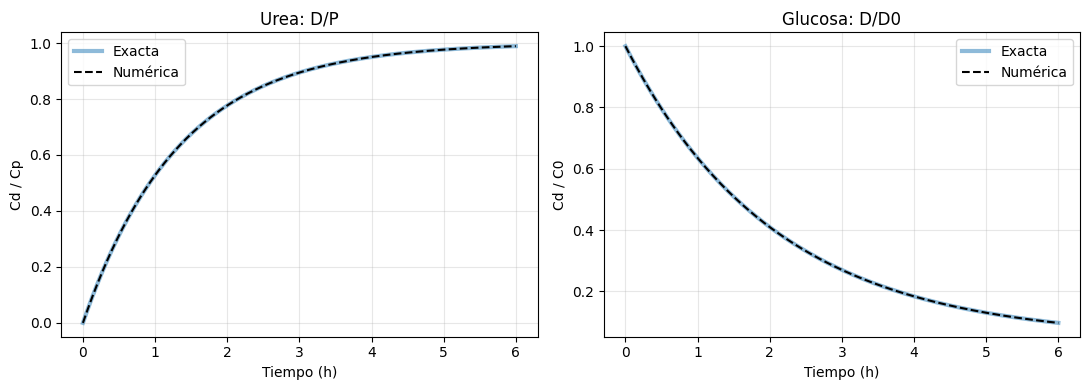

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Urea: D/P (qué tan cerca llega del equilibrio con el plasma)
Cd_num, Cd_ex = resultados["Urea"]
ax[0].plot(t / 60, Cd_ex / solutos["Urea"]["Cp"], label="Exacta", lw=3, alpha=.5)
ax[0].plot(t / 60, Cd_num / solutos["Urea"]["Cp"], "k--", label="Numérica")
ax[0].set_title("Urea: D/P"); ax[0].set_ylabel("Cd / Cp")

# Glucosa: D/D0 (cuánto se disipa)
Cd_num, Cd_ex = resultados["Glucosa"]
ax[1].plot(t / 60, Cd_ex / solutos["Glucosa"]["C0"], label="Exacta", lw=3, alpha=.5)
ax[1].plot(t / 60, Cd_num / solutos["Glucosa"]["C0"], "k--", label="Numérica")
ax[1].set_title("Glucosa: D/D0"); ax[1].set_ylabel("Cd / C0")

for a in ax:
    a.set_xlabel("Tiempo (h)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

#Ósmosis

En el Paso 1 el volumen V era constante y solo había difusión. Ahora el agua se mueve: la glucosa del dializado atrae agua desde la sangre (ósmosis), V crece, y esa agua extra diluye la glucosa. Es el mecanismo central de la ultrafiltración en diálisis peritoneal.

Conceptos

Presión osmótica (van ‘t Hoff, soluciones diluidas): un soluto genera una presión que atrae agua hacia donde hay más soluto:

π = R · T · C

A 37 °C, R·T ≈ 19.3 mmHg por cada mmol/L. Por eso 126 mmol/L de glucosa equivalen a unos 2400 mmHg de presión osmótica teórica. Es enorme comparada con la presión hidrostática (unos 12 mmHg), pero la membrana no la “siente” completa. Eso lo controla el siguiente concepto.

Coeficiente de reflexión σ (entre 0 y 1): mide qué fracción de la presión osmótica de un soluto actúa realmente sobre el agua. Si σ = 1, la membrana lo retiene por completo y el efecto osmótico es total. Si σ = 0, el soluto pasa libremente y no atrae agua. La glucosa pasa con relativa facilidad por los poros pequeños, así que su σ efectivo es bajo.

Ecuación de Starling (flujo de agua hacia la cavidad peritoneal):

Jv = Lp·S · [ (Pc − Pip) + σg · R·T · (Cd − Cp) − σonc · πonc ]





In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Constante física ---
R_gas = 0.082057        # L·atm/(mol·K)
T_corp = 310.15         # K (37 °C)
RT = R_gas * T_corp * 760.0 / 1000.0   # mmHg por mmol/L (1 atm = 760 mmHg)

# --- Membrana (valores ILUSTRATIVOS) ---
LpS = 0.074        # mL/min/mmHg, conductancia hidráulica total
sigma_g = 0.04     # reflexión efectiva de glucosa (sin unidades)
sigma_onc = 0.83   # reflexión efectiva de proteínas (sin unidades)
PS = 16.0          # mL/min, difusión de glucosa
Jl = 0.3           # mL/min, absorción linfática

# --- Presiones ---
Pc = 20.0          # mmHg, presión capilar
Pip0 = 8.0         # mmHg, presión intraperitoneal inicial
k_pip = 0.0        # mmHg/mL; 0 = presión intraperitoneal constante
pi_onc = 25.0      # mmHg, presión oncótica del plasma

# --- Soluto y volumen ---
Cp = 5.5           # mmol/L, glucosa en plasma
C0 = 126.0         # mmol/L, glucosa inicial del dializado (~2.27 %)
V0 = 2000.0        # mL, volumen inicial

print(f"R·T = {RT:.2f} mmHg por mmol/L")

R·T = 19.34 mmHg por mmol/L


funciones

In [21]:
def Jv_starling(V, N):
    """Flujo de agua (mL/min), positivo hacia la cavidad."""
    Cd = N / V
    Pip = Pip0 + k_pip * (V - V0)
    fuerza_hidrostatica = Pc - Pip
    fuerza_osmotica = sigma_g * RT * (Cd - Cp)
    fuerza_oncotica = sigma_onc * pi_onc
    return LpS * (fuerza_hidrostatica + fuerza_osmotica - fuerza_oncotica)

def modelo(t, y):
    V, N = y
    Cd = N / V
    dV = Jv_starling(V, N) - Jl
    dN = PS * (Cp - Cd) - Jl * Cd
    return [dV, dN]

verificaciones antes de simular

Antes de confiar en el modelo, comprobamos casos donde conocemos la respuesta:

In [22]:
# 1) R·T debe dar ~19.3
assert abs(RT - 19.34) < 0.05, "R·T fuera de lo esperado"

# 2) Cálculo a mano del flujo inicial
mano = LpS * ((Pc - Pip0) + sigma_g * RT * (C0 - Cp) - sigma_onc * pi_onc)
codigo = Jv_starling(V0, C0 * V0)
assert abs(mano - codigo) < 1e-12
print(f"Jv inicial = {codigo:.2f} mL/min")

# 3) Sin glucosa en el dializado (Cd = Cp) no hay fuerza osmótica
Jv_sin_glucosa = Jv_starling(V0, Cp * V0)
print(f"Jv con Cd = Cp: {Jv_sin_glucosa:.3f} mL/min (solo hidrostática − oncótica)")

# 4) Con sigma_g = 0 la glucosa no atrae agua
sg_guardado = sigma_g
sigma_g = 0.0
print(f"Jv con sigma_g = 0: {Jv_starling(V0, C0 * V0):.3f} mL/min")
sigma_g = sg_guardado

Jv inicial = 6.25 mL/min
Jv con Cd = Cp: -0.647 mL/min (solo hidrostática − oncótica)
Jv con sigma_g = 0: -0.647 mL/min


Los números de los casos 3 y 4 deben coincidir entre sí, porque en ambos desaparece el término osmótico.

In [24]:
t_eval = np.linspace(0, 360, 361)    # min
sol = solve_ivp(modelo, (0, 360), [V0, C0 * V0], t_eval=t_eval,
                method="LSODA", rtol=1e-8, atol=1e-8)
V, N = sol.y
Cd = N / V
Jv = np.array([Jv_starling(v, n) for v, n in zip(V, N)])

5: gráficas

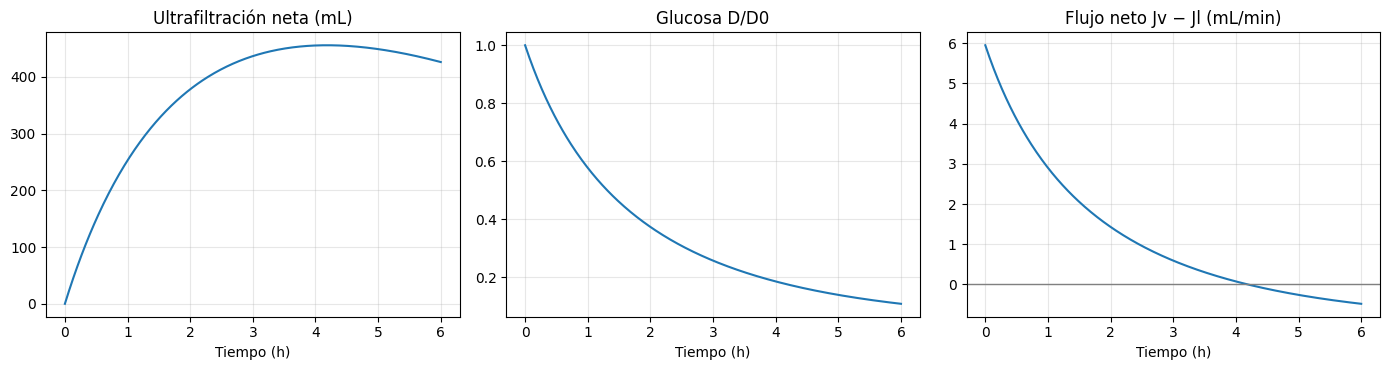

UF máxima: 456 mL a los 4.2 h
UF a 6 h:  426 mL


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(t_eval / 60, V - V0);   ax[0].set_title("Ultrafiltración neta (mL)")
ax[1].plot(t_eval / 60, Cd / C0);  ax[1].set_title("Glucosa D/D0")
ax[2].plot(t_eval / 60, Jv - Jl);  ax[2].set_title("Flujo neto Jv − Jl (mL/min)")
ax[2].axhline(0, color="gray", lw=1)
for a in ax:
    a.set_xlabel("Tiempo (h)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"UF máxima: {np.max(V - V0):.0f} mL a los {t_eval[np.argmax(V - V0)] / 60:.1f} h")
print(f"UF a 6 h:  {V[-1] - V0:.0f} mL")